## Noa Pereira Prada Schnor


###  PIMA INDIANS DIABETES DATASET

The Pima Indian Diabetes Dataset, originally from the National Institute of Diabetes and Digestive and Kidney Diseases, contains information of 768 women from a population near Phoenix, Arizona, USA. The outcome tested was Diabetes, 268 tested positive and 500 tested negative. Therefore, there is one target (dependent) variable and the following attributes (TYNECKI, 2018): 


	Pregnancies (number of times pregnant), 

	Oral glucose tolerance test - OGTT (two hour plasma glucose concentration after 75g anhydrous glucose in mg/dl), 

	Blood Pressure (Diastolic Blood Pressure in mmHg), 

	Skin Thickness (Triceps skin fold thickness in mm), 

	Insulin (2 h serum insulin in mu U/ml), 

	BMI (Body Mass Index in kg/m<sup>2</sup>), 

	Age (years),

	Pedigree Diabetes Function ('function that represents how likely they are to get the disease by extrapolating from their ancestor’s history')

### PIMA INDIANS AND DIABETES

Pima are descendants of people that inhabited the Sonoran desert and Sierra Madre areas for centuries. Around 300 B.C. they moved to Gila River Valley at the time  in Mexico, but region that was acquired by the United States in 1853. A Pima reservation was created in Arizona in 1959 and they adapted to their desert homeland by directing water to support a subsistence agriculture. Around 1900 the number of population of white settlers increased and a diversion of the water happened. That had an impact of Pima's food intake and way of life. Pima Indians used to farm sustained through physical labour to a little labour and scarce of food. As a consequence they food intake became high in fat and their lifestyle was mainly sedentary. That resulted in development of diabetes among the Arizona Pimas, and it drawed attention as they had the highest recorded prevalence and incidence of type 2 diabetes (T2DM) of any geographically-defined population (SCHULZ et al, 2015).
The Pima population has been under study by the National Institute of Diabetes and Digestive and Kidney Diseases at intervals of 2 years since 1965. As epidemiological evidence indicates that T2DM results from interaction of genetic and environmental factors, the Pima Indians Diabetes Dataset includes information about attributes that could and should be related to the onset of diabetes and its future complications.

### TRICEPS SKIN FOLD THICKNESS

Chandra-Selvi at al (2016) defined adipose tissue as a <i>'loose connective tissue composed mainly of adipocytes that has an unlimited growth potential at any stage of life, excess of adipose tissue predisposes to many diseases-development of insulin resistance'</i>. Their study found that the skinfold thickness gradually decreased in diabetic patients as the duration of disease increased. However, the Pima Indians Diabetes Dataset does not provide information on the duration of the Diabetes.  The researchers discussed the results and concluded that in diabetic patients, there is an efflux of free fatty acids from the adipose tissue, resulting in a decrease of skin fold thickness as the duration of disease increases (CHANDRA-SELVI at al, 2016). 
Neverthless, there is still very limited prospective information evaluating the relationship of skinfold thickness with incident T2DM (RUIZ-ALEJOS et al, 2020). 
Triceps skinfold thickness in millimeters for females aged 20 and over and number of examined persons, mean, standard error of the mean, and selected percentiles, by race and ethnicity and age: United States, 2007–2010 (FRYAR et al, 2012).

<a href="https://ibb.co/4NDNNx1"><img src="https://i.ibb.co/KyQyyHK/table-triceps-skin-fold.png" alt="table-triceps-skin-fold" border="0"></a>

### OBESITY AND DIABETES

Obesity, assessed by Body Mass Index (BMI), is intimately associated with diabetes and its impact on the development of T2DM has been largely described in large cohort prospective studies (VAN GAAL and SCHEEN, 2015; WILDING, 2014; RUIZ-ALEJOS et al, 2020). In fact, most of the individuals with T2DM are overweight or obese <sup>5</sup>.  Despite the link between obesity and T2DM not all obese develops diabetes and not all diabetics are obese people. Diabetic lean people probably have a stronger genetic component for T2DM than overweight and obese individuals (WILDING, 2014).
Accordingly to Ruiz-Alejos and col (2020) 'there is no specific recommendation about the use of an anthropometric measurement as a marker for T2DM risk prediction besides BMI and waist circumference'. Unfortunately the waist circumference is a measurement not included in the Pima Indians Diabetes Dataset.
BMI provides a simple, yet accurate method for indicating nutritional status in adults (as it can be seem in the Table below), and it can be calculated by dividing the individual's weight (in kg) by the square of their height (in metres).
<img src="https://i.ibb.co/647ZL2X/bmi.png" alt="bmi" border="0">

<img src="https://i.ibb.co/HTqTfdr/WHO-Europe-Nutrition-Body-mass-index-BMI.png" alt="WHO-Europe-Nutrition-Body-mass-index-BMI" border="0">
Table. Nutritional Status. Source: World Health Organization.

## OBJECTIVE

The objective of this project is:
1. Analyse the dataset under the point of view of a Dietitian.
2. Apply machine learning techniques resulting in bridging the gap between datasets and human knowledge. 

In [5]:
#Load packages

import pandas as pd
import numpy as np
import seaborn as sns
import sklearn.model_selection as mod
import sklearn.neighbors as nei
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import LeaveOneOut
from sklearn import metrics
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score, classification_report, precision_recall_curve, average_precision_score 
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import cross_val_score
from sklearn.feature_selection import RFECV
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import operator
%matplotlib inline

In [6]:
url = "dataset/diabetes.csv"  # letakkan diabetes.csv di folder yang sama dengan notebook
# fallback jika file lokal tidak ada:
# url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"

In [7]:
#Load CSV file using Pandas

pima = pd.read_csv(url)
num_cols = list(pima.columns)  # 9 kolom numerik asli (sebelum kolom kategori ditambahkan)

#### Check the DataFrame & Descriptive Statistics and Analysis of Pima Indians Dataset

In [8]:
# Check dimension of the DataFrame

pima.shape

(768, 9)

In [9]:
# Check the type of 'pima'
type(pima)

pandas.DataFrame

In [10]:
# Get row indices 

pima_row_idx = pima.index
pima_row_idx

RangeIndex(start=0, stop=768, step=1)

In [11]:
# Get the column names 

pima_col_idx = pima.columns
pima_col_idx

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

In [12]:
# Get data type for each attribute 

pima.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [13]:
# Check the first 5 rows

pima.head (5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [14]:
# Check missing values

pima.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [15]:
# Create Nutritional status column 

Nutritional_status = pd.Series(index=pima.index, dtype=object) 

In [16]:
# Nutritional status based on BMI

for i in range(len(pima)): 
    if pima['BMI'][i] == 0.0: 
        Nutritional_status[i]="NA"
    
    elif pima['BMI'][i] < 18.5: 
        Nutritional_status[i]="Underweight"
        
    elif pima['BMI'][i] < 25: 
        Nutritional_status[i]="Normal"
  
    elif pima['BMI'][i] >= 25 and pima['BMI'][i] < 30: 
        Nutritional_status[i]="Overweight"
  
    elif pima['BMI'][i] >= 30: 
        Nutritional_status[i]="Obese"
        
    else: 
        Nutritional_status[i]= pima['BMI'][i] 

In [17]:
# Insert new column - Nutritional Status
pima.insert(6, "Nutritional Status", Nutritional_status)

In [18]:
# Check df containing new column
pima.head (5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Nutritional Status,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,Obese,0.627,50,1
1,1,85,66,29,0,26.6,Overweight,0.351,31,0
2,8,183,64,0,0,23.3,Normal,0.672,32,1
3,1,89,66,23,94,28.1,Overweight,0.167,21,0
4,0,137,40,35,168,43.1,Obese,2.288,33,1


In [19]:
pima['Nutritional Status'].value_counts()

Nutritional Status
Obese          472
Overweight     179
Normal         102
NA              11
Underweight      4
Name: count, dtype: int64

##### 11 women don't have information about BMI. Only 102 of 768 women have normal weight. Most of the women present overweight or obesity.

In [20]:
# Create OGTT_Interpretation (Interpretation of Glucose level) column 

OGTT_Interpretation = pd.Series(index=pima.index, dtype=object) 

In [21]:
# Interpretation of OGTT (Glucose) - using OGTT levels recommended by DIABETES UK (2019)

for i in range(len(pima)): 
    if pima['Glucose'][i] == 0.0: 
        OGTT_Interpretation [i]="NA"
    
    elif pima['Glucose'][i] <= 140: 
        OGTT_Interpretation [i]="Normal"
    
    elif (pima['Glucose'][i] > 140) & (pima['Glucose'][i] <= 198): 
        OGTT_Interpretation [i]="Impaired Glucose Tolerance"
        
    elif pima['Glucose'][i] > 198: 
        OGTT_Interpretation[i]="Diabetic Level"
        
    else: 
        OGTT_Interpretation [i]= pima['Glucose'][i] 

In [22]:
# Insert new column - Glucose Result
pima.insert(2, "Glucose Result", OGTT_Interpretation)

In [23]:
pima['Glucose Result'].value_counts()

Glucose Result
Normal                        571
Impaired Glucose Tolerance    191
NA                              5
Diabetic Level                  1
Name: count, dtype: int64

##### Hanya 1 perempuan yang berada pada level "Diabetic" (glukosa > 198 mg/dl) dan 191 berada pada "Impaired Glucose Tolerance". (Versi lama notebook salah menghitung karena bug operator `&`.) Menarik jika HOMA-IR dihitung untuk menilai resistensi insulin pada sampel.

In [24]:
Impaired_Glucose_Tolerance_Diabetic = ((pima ['Glucose'] > 140 ) & (pima ['Glucose'] <= 198) & (pima ['Outcome'] == 1)).sum()
Impaired_Glucose_Tolerance_Diabetic

np.int64(131)

##### Dari 191 perempuan dengan toleransi glukosa terganggu, 131 positif diabetes. Sisanya berisiko berkembang menjadi diabetes atau diabetes yang belum terdiagnosis.

In [25]:
Normal_Glucose_Diabetic = ((pima ['Glucose'] != 0 ) & (pima ['Glucose'] <= 140) & (pima ['Outcome'] == 1)).sum()
Normal_Glucose_Diabetic

np.int64(134)

##### 134 dari 268 perempuan diabetes (sekitar setengahnya) memiliki glukosa normal. Informasi terapi obat diperlukan.

In [26]:
# Create Percentile of skin thickness column

Percentile_skin_thickness = pd.Series(index=pima.index, dtype=object) 

In [27]:
# Check how many women are 80 or older (the Percentile skin thickeness depend of skin fold and age)

pima['Age'].value_counts()

Age
22    72
21    63
25    48
24    46
23    38
28    35
26    33
27    32
29    29
31    24
41    22
30    21
37    19
42    18
33    17
32    16
38    16
36    16
45    15
34    14
43    13
46    13
40    13
39    12
35    10
50     8
51     8
44     8
52     8
58     7
54     6
47     6
53     5
57     5
60     5
48     5
49     5
62     4
55     4
66     4
63     4
59     3
56     3
65     3
67     3
61     2
69     2
72     1
81     1
64     1
70     1
68     1
Name: count, dtype: int64

In [28]:
#  Check skin fold thickness Percentile

for i in range(len(pima)): 
    
    
    if pima["Age"][i] >= 20.0 and pima["Age"][i] <= 79.0: 
        
        if pima["SkinThickness"][i] == 0.0: 
            Percentile_skin_thickness[i]=" 0 NA"
    
        elif pima["SkinThickness"][i] < 11.9: 
            Percentile_skin_thickness[i]="1 <P5th"
        
        elif pima["SkinThickness"][i] == 11.9: 
            Percentile_skin_thickness[i]="2 P5th"
        
        elif pima["SkinThickness"][i] > 11.9 and pima["SkinThickness"][i] < 14.0: 
            Percentile_skin_thickness[i]="3 P5th - P10th"
        
        elif pima["SkinThickness"][i] == 14.0: 
            Percentile_skin_thickness[i]="4 P10th"
        
        elif pima["SkinThickness"][i] > 14.0 and  pima["SkinThickness"][i] < 15.8: 
            Percentile_skin_thickness[i]="5 P10th - P15th"
        
        elif pima["SkinThickness"][i] == 15.8: 
            Percentile_skin_thickness[i]="6 P15th"
    
        elif pima["SkinThickness"][i] > 15.8 and pima["SkinThickness"][i] < 18.0: 
            Percentile_skin_thickness[i]="7 P15th - P25th"
    
        elif pima["SkinThickness"][i] == 18.0: 
            Percentile_skin_thickness[i]="8 P25th"
        
        elif pima["SkinThickness"][i] > 18.0 and pima["SkinThickness"][i] < 23.5: 
            Percentile_skin_thickness[i]="9 P25th - P50th"
   
        elif pima["SkinThickness"][i] == 23.5: 
            Percentile_skin_thickness[i]="10 P50th"
        
        elif pima["SkinThickness"][i] > 23.5 and pima["SkinThickness"][i] < 29.0: 
            Percentile_skin_thickness[i]="11 P50th - P75th"
        
        elif pima["SkinThickness"][i] == 29.0: 
            Percentile_skin_thickness[i]="12 P75th"
        
        elif pima["SkinThickness"][i] > 29.0 and pima["SkinThickness"][i] < 31.9: 
            Percentile_skin_thickness[i]="13 P75th - P85th"
        
        elif pima["SkinThickness"][i] == 31.9: 
            Percentile_skin_thickness[i]="14 P85th"
        
        elif pima["SkinThickness"][i] > 31.9 and pima["SkinThickness"][i] < 33.7: 
            Percentile_skin_thickness[i]="15 P85th - P90th"
    
        elif pima["SkinThickness"][i] == 33.7: 
            Percentile_skin_thickness[i]="16 P90th"
        
        elif pima["SkinThickness"][i] > 33.7 and pima["SkinThickness"][i] < 35.9: 
            Percentile_skin_thickness[i]="17 P90th - P95th"
    
        elif pima["SkinThickness"][i] == 35.9: 
            Percentile_skin_thickness[i]="18 P95th"
        
        elif pima["SkinThickness"][i] > 35.9: 
            Percentile_skin_thickness[i]="19 >P95th"
            
    elif pima["Age"][i] >= 80.0:  #Only 1 woman is 81 years old
        if  pima["SkinThickness"][i] > 31.7: 
            Percentile_skin_thickness[i]="20 >P95th"


<i>**Note**</i>: As I have 2 >P95 I chose to add numbers in front of each percentile to easily visualize which >P95 it belonged. 

In [29]:
# Insert new column - Percentile of skin thickness

pima.insert(4, "Percentile skin thickness", Percentile_skin_thickness)

In [30]:
# Check the first 5 rows

pima.head(5)

,Pregnancies,Glucose,Glucose Result,BloodPressure,Percentile skin thickness,SkinThickness,Insulin,BMI,Nutritional Status,DiabetesPedigreeFunction,Age,Outcome
0,6,148,Impaired Glucose Tolerance,72,17 P90th - P95th,35,0,33.6,Obese,0.627,50,1
1,1,85,Normal,66,12 P75th,29,0,26.6,Overweight,0.351,31,0
2,8,183,Impaired Glucose Tolerance,64,0 NA,0,0,23.3,Normal,0.672,32,1
3,1,89,Normal,66,9 P25th - P50th,23,94,28.1,Overweight,0.167,21,0
4,0,137,Normal,40,17 P90th - P95th,35,168,43.1,Obese,2.288,33,1


##### It looks like the Percentile of the triceps skin fold thickness can predict the Nutritional Status.

In [31]:
# Check number of women x Percentile of skin thickness

pima['Percentile skin thickness'].value_counts()

Percentile skin thickness
 0 NA               227
19 >P95th           145
11 P50th - P75th     87
9 P25th - P50th      79
15 P85th - P90th     50
13 P75th - P85th     46
17 P90th - P95th     23
8 P25th              20
7 P15th - P25th      20
3 P5th - P10th       18
12 P75th             17
1 <P5th              15
5 P10th - P15th      14
4 P10th               6
20 >P95th             1
Name: count, dtype: int64

##### 227 women don't have information regarding skin fold. Most of the sample have Percentile of skin thickness greater than 95th. 53 women had value below P15 indicating that they might be malnourished. Only one woman is 80 years old or older and she presents a Percentile of skin thickness greater than 95th. 

In [32]:
diabetic_malnourished_st = ((pima ['SkinThickness'] > 0) & (pima ['SkinThickness'] < 15.8) & (pima ['Outcome'] == 1)).sum()
diabetic_malnourished_st

np.int64(6)

In [33]:
diabetic_malnourished_bmi = ((pima ['BMI'] > 0) & (pima ['BMI'] < 18.5) & (pima ['Outcome'] == 1)).sum()
diabetic_malnourished_bmi

np.int64(0)

In [34]:
diabetic_malnourished_bmi_st = ((pima ['BMI'] > 0) & (pima ['BMI'] < 18.5) & (pima ['SkinThickness'] > 0) & (pima ['SkinThickness'] < 15.8) & (pima ['Outcome'] == 1)).sum()
diabetic_malnourished_bmi_st

np.int64(0)

##### Berdasarkan skin thickness saja, 6 perempuan diabetes tergolong underweight/malnutrisi (<P15), sedangkan berdasarkan BMI maupun BMI & skin thickness tidak ada (0). (Angka lama 94 dan 2 keliru karena nilai 0 = data hilang ikut terhitung.) Skinfold thickness sulit diukur secara presisi tanpa pelatihan, sehingga jarang dipakai dan bervariasi pada diabetes, menopause, dan status hidrasi. Dataset ini perlu data tambahan untuk mengidentifikasi malnutrisi dengan skinfold.

In [35]:
# Minimum

In [36]:
pima.min()

Pregnancies                               0
Glucose                                   0
Glucose Result               Diabetic Level
BloodPressure                             0
Percentile skin thickness              0 NA
SkinThickness                             0
Insulin                                   0
BMI                                     0.0
Nutritional Status                       NA
DiabetesPedigreeFunction              0.078
Age                                      21
Outcome                                   0
dtype: object

##### It can be seem that only adult women were included as the minimum age is 21 years old. It can be noticed that a number of women don't have information of some of the attributes, such as glucose, blood pressure, etc as the minimum value is zero. 

In [37]:
# Maximum

In [38]:
pima.max()

Pregnancies                               17
Glucose                                  199
Glucose Result                        Normal
BloodPressure                            122
Percentile skin thickness    9 P25th - P50th
SkinThickness                             99
Insulin                                  846
BMI                                     67.1
Nutritional Status               Underweight
DiabetesPedigreeFunction                2.42
Age                                       81
Outcome                                    1
dtype: object

###### The nutritional status 'underweight' should not be classified as Max Value in medical point of view. However, it was considered as a Max value as it starts with the letter U.

In [39]:
#Check if the sample were classified as Underweight presented a BMI lower than 18.5

pima_underweight = pima[pima['Nutritional Status'] =='Underweight']
pima_underweight

,Pregnancies,Glucose,Glucose Result,BloodPressure,Percentile skin thickness,SkinThickness,Insulin,BMI,Nutritional Status,DiabetesPedigreeFunction,Age,Outcome
239,0,104,Normal,76,0 NA,0,0,18.4,Underweight,0.582,27,0
418,1,83,Normal,68,0 NA,0,0,18.2,Underweight,0.624,27,0
438,1,97,Normal,70,5 P10th - P15th,15,0,18.2,Underweight,0.147,21,0
526,1,97,Normal,64,9 P25th - P50th,19,82,18.2,Underweight,0.299,21,0


In [40]:
pima['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

##### 500 not diabetic and 268 are diabetic 

In [41]:
# Another way of counting the outcome (diabetes)
count_not_diabetic = len(pima[pima['Outcome']==0])
count_not_diabetic

500

In [42]:
# Check the average of features grouped by Outcome (Diabetes)

pima.groupby('Outcome').mean(numeric_only=True)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.298000,109.980000,68.184000,19.664000,68.792000,30.304200,0.429734,31.190000
1,4.865672,141.257463,70.824627,22.164179,100.335821,35.142537,0.550500,37.067164


##### It looks like the average of all features is higher in diabetic women.

In [43]:
pima.mean(numeric_only=True)

Pregnancies                   3.845052
Glucose                     120.894531
BloodPressure                69.105469
SkinThickness                20.536458
Insulin                      79.799479
BMI                          31.992578
DiabetesPedigreeFunction      0.471876
Age                          33.240885
Outcome                       0.348958
dtype: float64

##### As some of the women have no information of a number of attributes, such as glucose, blood pressure and BMI the average of those items might not be correct. To get the correct value only the women with a value > zero should be included to calculate the average.

In [44]:
# Shows women that contains information about Glucose

pima_glucose = pima.loc[pima['Glucose'] != 0]

In [45]:
pima_glucose.shape

(763, 12)

##### Most women of the sample have data regarding glucose (only 5 of them don't have any glucose value) as it is an important information to check the health status of a diabetic person.

In [46]:
# Check average of glucose from women that don't have zero value of glucose

In [47]:
pima_glucose['Glucose'].mean()

np.float64(121.6867627785059)

##### The average of glucose is at the normal range (less than 140 mg/dl).

In [48]:
pima_glucose.groupby('Outcome').mean(numeric_only=True)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.311871,110.643863,68.213280,19.631791,69.160966,30.317304,0.430662,31.247485
1,4.860902,142.319549,70.800752,22.056391,101.090226,35.106015,0.550605,37.052632


In [49]:
# Check minimum and maximum values of glucose from women that don't have zero value of glucose

In [50]:
pima_glucose['Glucose'].min()

np.int64(44)

In [51]:
pima_glucose['Glucose'].max()

np.int64(199)

##### As it shows above, some women have information about glucose but no information about insulin. Moreover, it shows that 5 women don't have information about glucose as the result shows 763 rows. Furthermore, the maximum value of glucose is 199, considered a Diabetic level. Therefore, even diagnosed with diabetes they don't present high glucose value. The dataset should have information about drug therapy.

In [52]:
# Shows women that have information about Blood pressure

pima_BloodPressure = pima.loc[pima['BloodPressure'] != 0]

In [53]:
pima_BloodPressure.shape

(733, 12)

In [54]:
# Check the average of blood pressure (only from women that don't have zero value of Blood Pressure)

pima_BloodPressure['BloodPressure'].mean()

np.float64(72.40518417462484)

In [55]:
# Minimum and maximum of Blood Pressure from women that don't have zero value of Blood Pressure

In [56]:
pima_BloodPressure['BloodPressure'].min()

np.int64(24)

In [57]:
pima_BloodPressure['BloodPressure'].max()

np.int64(122)

##### 35 women don't have information about Blood Pressure as the result shows 733 rows.  The maximum value of Diastolic Blood Pressure shows that there are a possibility of some women to have hypertension (>90 mmHg) as it can be diagnosed when the blood pressure is 140/90 mmHg or higher (NICE, 2019). Diabetic individuals should be treated to Diastolic blood pressure goal of  less than 90 mmHg. It is recommended that blood pressure should be measured at least annually in an adult with type 2 diabetes without previously diagnosed hypertension or renal disease (NICE, 2019). Systolic Blood Pressure measure should have been included in this dataset as studies show that blood pressure equal or greater than 115/75 mmHg is associated with increased rates of several diseases, including heart failure, kidney disease and mortality (BOER et al, 2017). Looking at the minimum value of Diastolic Blood Pressure (24 mmHg) it is totally out of the normal range even when the heart is 'relaxing' (between 40 to 160 mmHg). Individual with Diastolic blood pressure less or equal to 60 mmHg has low blood pressure (BLOOD PRESSURE UK).

In [58]:
pima_insulin = pima.loc[pima['Insulin'] != 0]

In [59]:
pima_insulin.shape

(394, 12)

In [60]:
# Check average value of insulin from women that don't have zero value of insulin

pima_insulin['Insulin'].mean()

np.float64(155.5482233502538)

In [61]:
# Check minimum and maximum of Insulin value from women that don't have zero value of insulin

In [62]:
pima_insulin['Insulin'].min()

np.int64(14)

In [63]:
pima_insulin['Insulin'].max()

np.int64(846)

###### Normal range of 2h insulin is from 16 to 166 mIU/L. The average value of 2h insulin of the samples show a normal range. However, some women of the sample seem to present high level of insulin level. It might be due obesity, early stage of T2DM or excessive insulin administration.

In [64]:
# Check women that don't have zero value of BMI

pima_BMI = pima.loc[pima['BMI'] != 0]

In [65]:
pima_BMI.shape

(757, 12)

In [66]:
# Check average of BMI from women that don't have zero value of BMI

pima_BMI['BMI'].mean()

np.float64(32.457463672391015)

##### The average value of BMI indicates obesity (BMI >= 30 kg/m2)

In [67]:
# Check minimun and maximum value of BMI from women that don't have zero value of BMI

In [68]:
pima_BMI['BMI'].min()

np.float64(18.2)

In [69]:
pima_BMI['BMI'].max()

np.float64(67.1)

##### The minimum value of BMI shows that there is no case of underweight, but the maximum value shows cases of women with morbid obesity (BMI >= 40kg/m2).

In [70]:
# Check only the women that have all the values of BMI, Glucose, Insulin and Blood Pressure

pima_all = pima.loc[(pima['BMI'] != 0) & (pima['Insulin'] != 0) & (pima['BloodPressure'] != 0) & (pima['Glucose'] != 0)]

In [71]:
pima_all.shape

(392, 12)

##### Only 392 women have information about all the attributes. That number represents less than half of the sample (around 49% of the women of the sample have all information of all attributes).

In [72]:
pima_all['Outcome'].value_counts()

Outcome
0    262
1    130
Name: count, dtype: int64

##### 262 women don't have DM and 130 have DM.

In [73]:
pima_all.mean(numeric_only=True)

Pregnancies                   3.301020
Glucose                     122.627551
BloodPressure                70.663265
SkinThickness                29.145408
Insulin                     156.056122
BMI                          33.086224
DiabetesPedigreeFunction      0.523046
Age                          30.864796
Outcome                       0.331633
dtype: float64

In [74]:
pima_all.groupby('Outcome').mean(numeric_only=True)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,2.721374,111.431298,68.969466,27.251908,130.854962,31.750763,0.472168,28.347328
1,4.469231,145.192308,74.076923,32.961538,206.846154,35.777692,0.625585,35.938462


##### Diabetic women tend to have higher number of pregnancies, higher level of glucose, higher Blood Pressure, Skin Thickness, Insulin, BMI, Diabetes Pedigree Function and Age. Both groups present BMI that indicates obesity. Women that have Diabetes have an average of insulin that is higher than the normal range (16 - 166  mIU/L). Both groups have average of glucose higher than the normal range (<= 100 mg/dL). It might indicate that some non diabetic women are in risk of have Diabetes in the future, specially the ones with higher levels of insulin (that might have insulin resistance).

In [75]:
pima_all.min()

Pregnancies                                           0
Glucose                                              56
Glucose Result               Impaired Glucose Tolerance
BloodPressure                                        24
Percentile skin thickness                       1 <P5th
SkinThickness                                         7
Insulin                                              14
BMI                                                18.2
Nutritional Status                               Normal
DiabetesPedigreeFunction                          0.085
Age                                                  21
Outcome                                               0
dtype: object

In [76]:
pima_all.max()

Pregnancies                               17
Glucose                                  198
Glucose Result                        Normal
BloodPressure                            110
Percentile skin thickness    9 P25th - P50th
SkinThickness                             63
Insulin                                  846
BMI                                     67.1
Nutritional Status               Underweight
DiabetesPedigreeFunction                2.42
Age                                       81
Outcome                                    1
dtype: object

In [77]:
diabetic_malnourished = ((pima_all ['SkinThickness'] < 15.8) & (pima_all ['Outcome'] == 1)).sum()
diabetic_malnourished

np.int64(4)

##### 4 from 130 Diabetic women are malnourished.

In [78]:
diabetic_overweight_obese = ((pima_all ['BMI'] >= 25) & (pima_all ['Outcome'] == 1)).sum()
diabetic_overweight_obese

np.int64(128)

##### 128 dari 130 perempuan diabetes (pada subset data lengkap) overweight atau obesitas (BMI >= 25); 110 di antaranya obesitas (BMI >= 30). (Angka lama 20 berasal dari kondisi terbalik `<= 30`.)

### Attributes Distribution

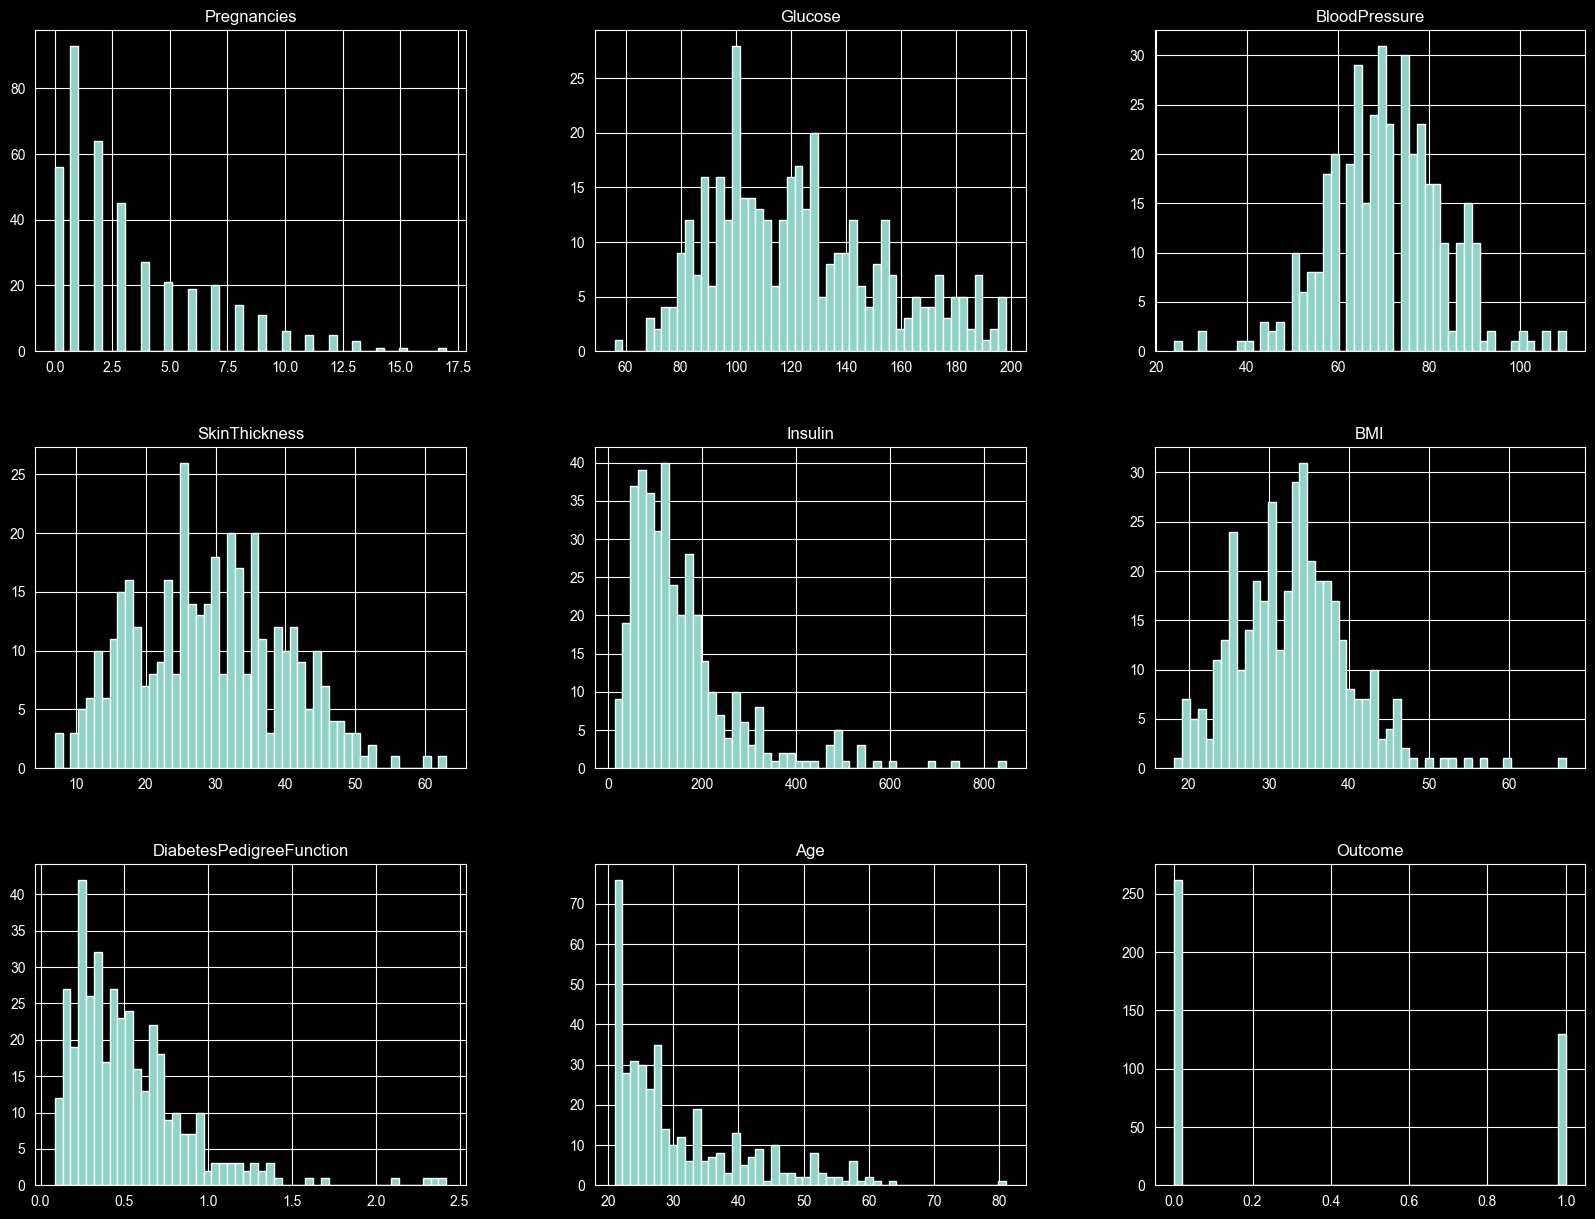

In [79]:
# Histogram
pima_all.hist(bins=50, figsize=(20, 15))
plt.show()

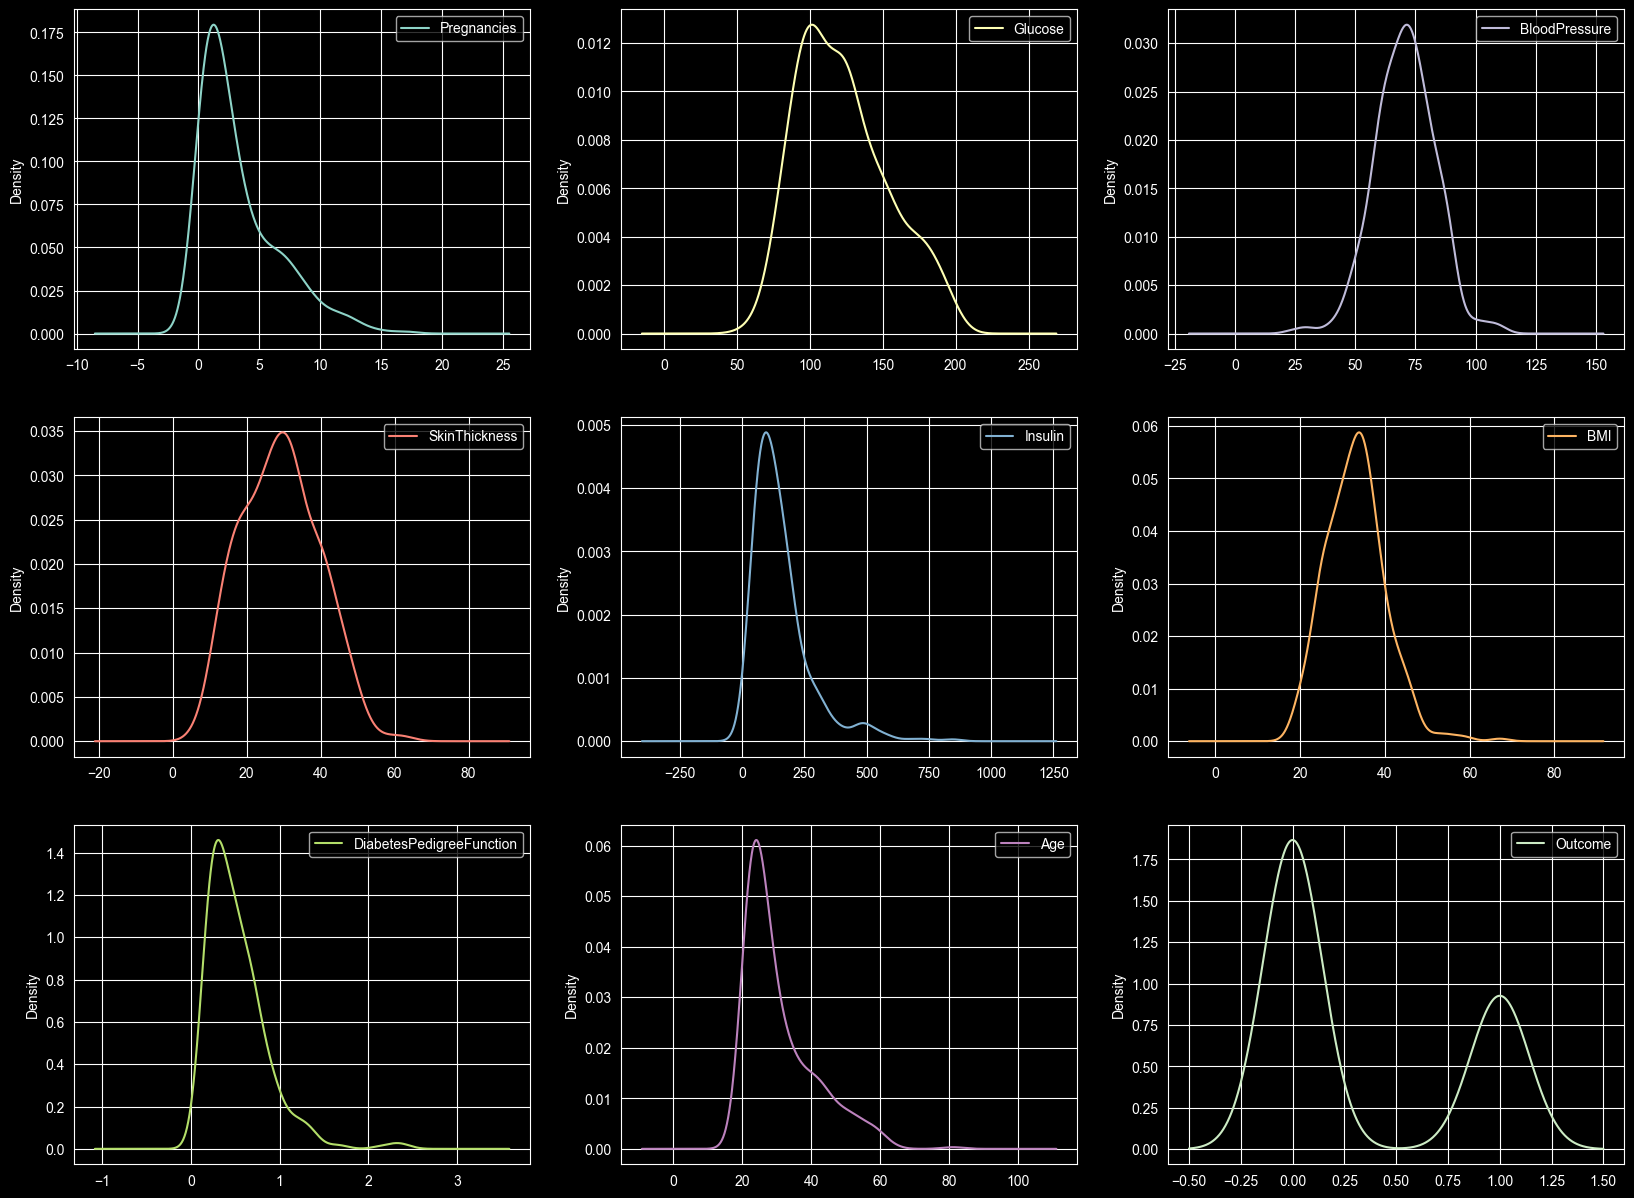

In [80]:
# Density plots for all attributes to visualize the distribution of each attribute
pima_all.plot(kind='density', subplots=True, layout=(3,3), figsize=(20, 15), sharex=False)
plt.show()

Pregnancies                    Axes(0.125,0.653529;0.227941x0.226471)
Glucose                     Axes(0.398529,0.653529;0.227941x0.226471)
BloodPressure               Axes(0.672059,0.653529;0.227941x0.226471)
SkinThickness                  Axes(0.125,0.381765;0.227941x0.226471)
Insulin                     Axes(0.398529,0.381765;0.227941x0.226471)
BMI                         Axes(0.672059,0.381765;0.227941x0.226471)
DiabetesPedigreeFunction           Axes(0.125,0.11;0.227941x0.226471)
Age                             Axes(0.398529,0.11;0.227941x0.226471)
Outcome                         Axes(0.672059,0.11;0.227941x0.226471)
dtype: object

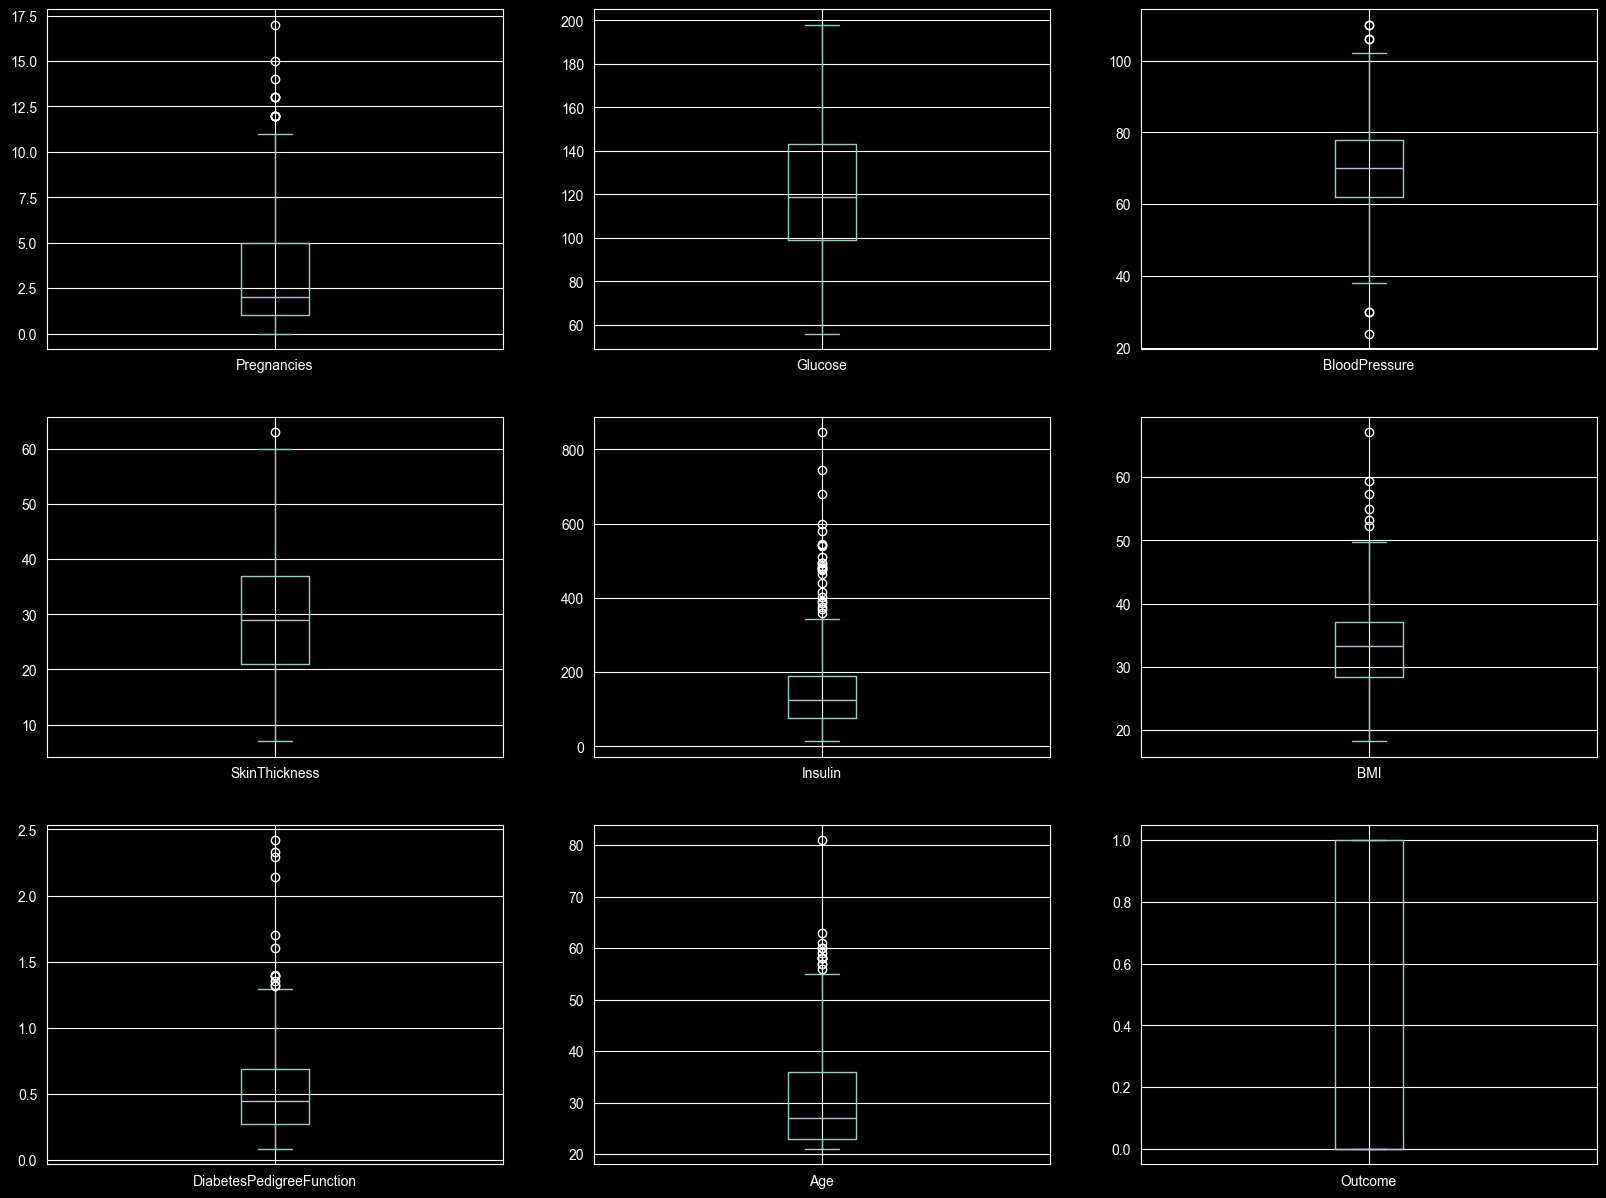

In [81]:
#Box and Whisker plot to visualize the distribution of all atributes
pima_all.plot(kind= 'box' , subplots=True, layout=(3,3), sharex=False, sharey=False, figsize=(20,15))

In [82]:
#Skew of attributes distributions
skew = pima_all[num_cols].skew()  # axis=0: skewness per fitur
skew

Pregnancies                 1.335596
Glucose                     0.517850
BloodPressure              -0.087516
SkinThickness               0.209311
Insulin                     2.165116
BMI                         0.663485
DiabetesPedigreeFunction    1.959101
Age                         1.403607
Outcome                     0.717990
dtype: float64

##### Bell shape curve: Blood Pressure (skew -0.09)
##### Right-Skewed: Insulin (2.17), Diabetes Pedigree Function (1.96), Age (1.40), Pregnancies (1.34)

##### Short IQR: insulin, Diabetes Pedigree Function, Blood Pressure and BMI
##### At least 75% of the women:
+ are 25 years old or older
+ have BMI nearly 30 kg/m2
+ have insulin level 100 or more
+ have 1 or more pregnancies
+ have glucose level of 100 mg/dL or more
+ have blood pressure of 60 mmHg or more 

##### Short IQR: insulin, Diabetes Pedigree Function, Blood Pressure and BMI
##### At least 75% of the women:
+ are 25 years old or older
+ have BMI nearly 30 kg/m2
+ have insulin level 100 or more
+ have 1 or more pregnancies
+ have glucose level of 100 mg/dL or more
+ have blood pressure of 60 mmHg or more 

## Correlation

In [83]:
# Correlation between the different characteristics. Closer to 1 better is the correlation.

corr_matrix_pearson = pima_all[num_cols].corr(method='pearson')
corr_matrix_pearson

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.198291,0.213355,0.093209,0.078984,-0.025347,0.007562,0.679608,0.256566
Glucose,0.198291,1.000000,0.210027,0.198856,0.581223,0.209516,0.140180,0.343641,0.515703
BloodPressure,0.213355,0.210027,1.000000,0.232571,0.098512,0.304403,-0.015971,0.300039,0.192673
SkinThickness,0.093209,0.198856,0.232571,1.000000,0.182199,0.664355,0.160499,0.167761,0.255936
Insulin,0.078984,0.581223,0.098512,0.182199,1.000000,0.226397,0.135906,0.217082,0.301429
BMI,-0.025347,0.209516,0.304403,0.664355,0.226397,1.000000,0.158771,0.069814,0.270118
DiabetesPedigreeFunction,0.007562,0.140180,-0.015971,0.160499,0.135906,0.158771,1.000000,0.085029,0.209330
Age,0.679608,0.343641,0.300039,0.167761,0.217082,0.069814,0.085029,1.000000,0.350804
Outcome,0.256566,0.515703,0.192673,0.255936,0.301429,0.270118,0.209330,0.350804,1.000000


#### There are no strong correlation between the features. The 'strongest' ones are the following (as expected):
+ Age x pregnancies (0.68) - Older women tend to have higher number of pregnancies
+ Glucose x insulin (0.58)
+ Glucose x outcome (0.52) - Women that have higher level of glucose tend to have higher level of insulin and have DM 
+ Skin fold thickness x BMI (0.66)  - Women with higher skin fold thickness value have higher BMI (and probably are overweight/obese)

##### Negative correlation:
+ BMI x Pregnancies (-0.025)
+ Blood Pressure x Diabetes Pedigree Function (-0.016)

<Axes: >

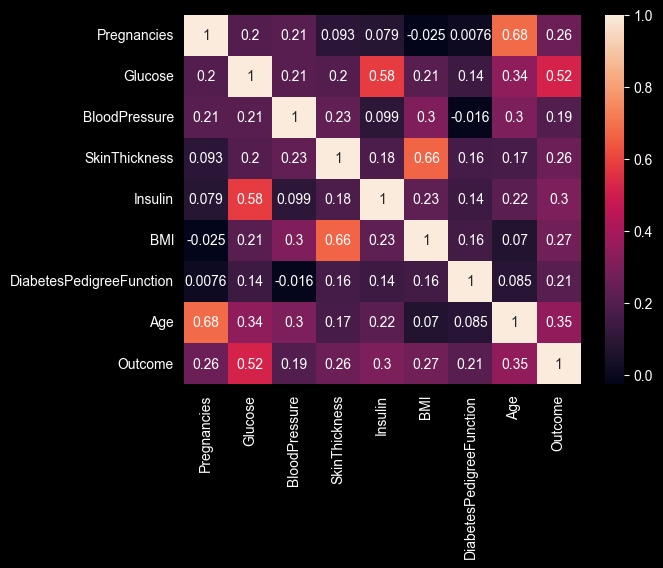

In [84]:
sns.heatmap(corr_matrix_pearson, annot = True)

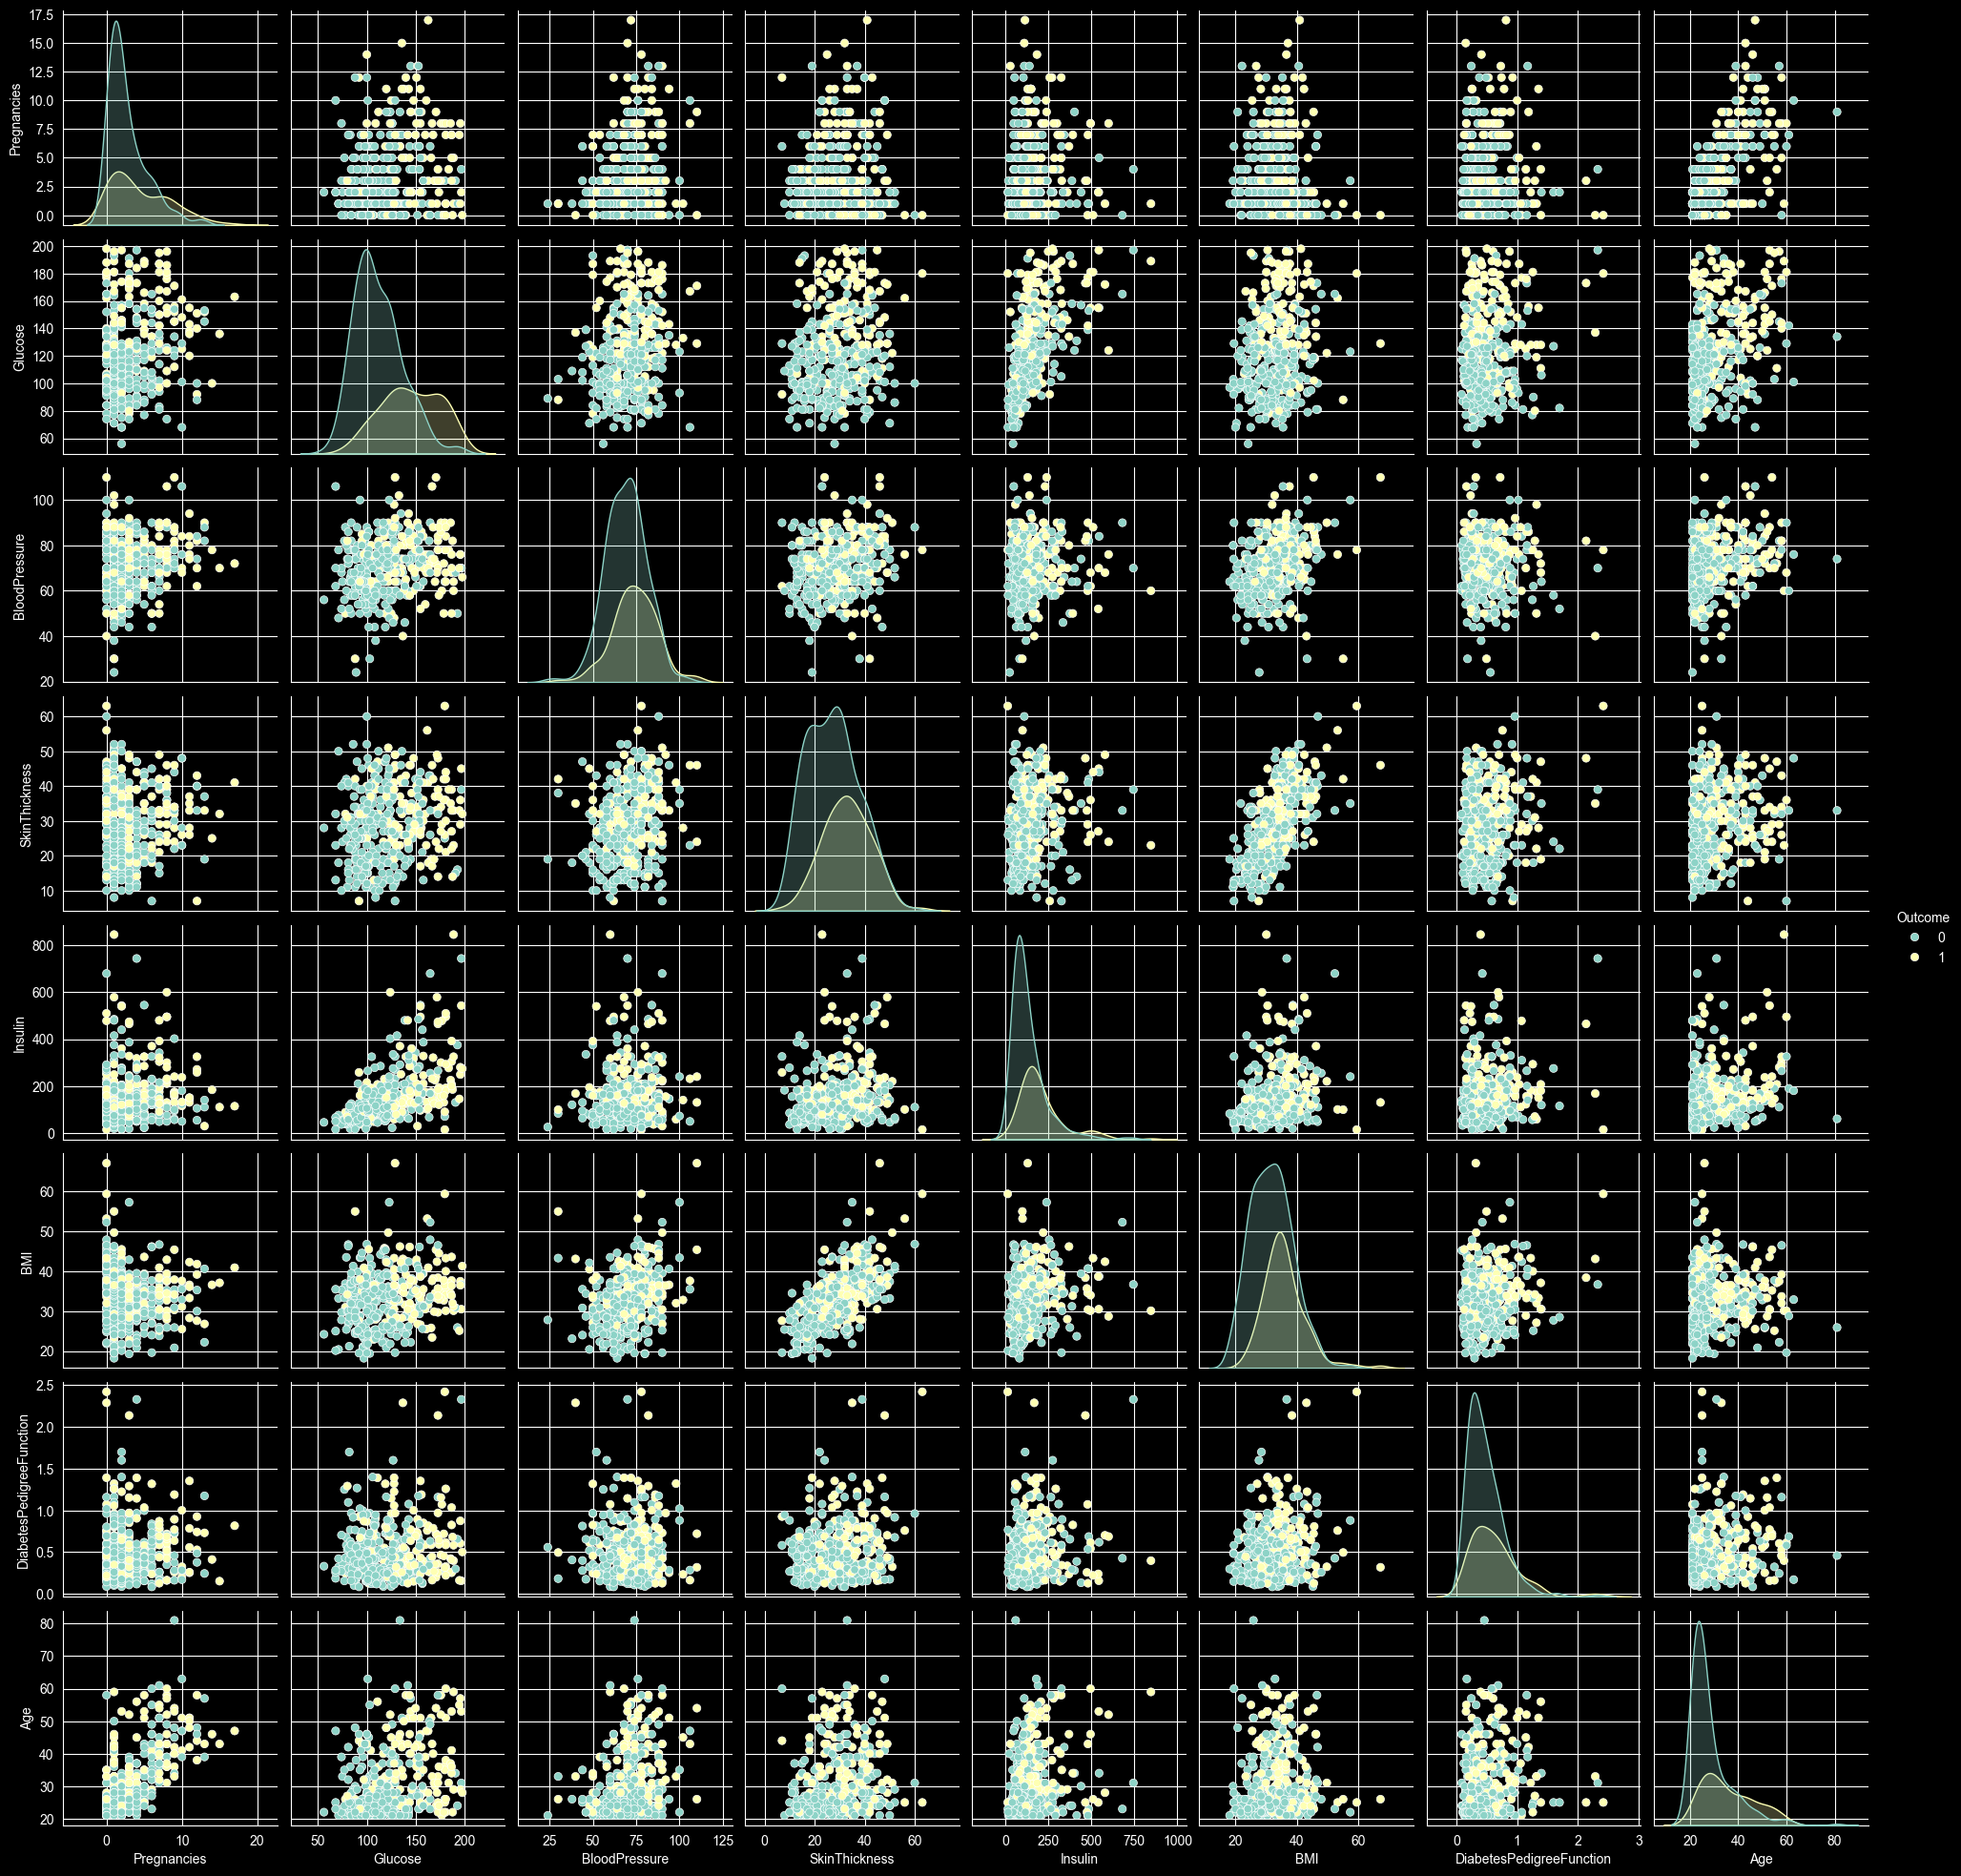

In [85]:
# Pairplot

sns.pairplot(pima_all[num_cols], hue='Outcome')

##### Diabetic women tend to show larger values of age, BMI, insulin, skin thickness, blood pressure, and pregnancies.
##### The feature that it is possible to see 2 distinct groups (diabetic and non diabetic) is glucose.

##### https://www.collaborat.com/pima-diabetes-data-discovery-predictive-model/

## Logic Regression

In [86]:
#1st Iteration - 8 variables
var1=["Pregnancies", "Glucose","BloodPressure","SkinThickness","Insulin", "BMI","DiabetesPedigreeFunction", "Age"]
X=sm.add_constant(pima_all[var1])  # intercept wajib ditambahkan pada statsmodels
y=pima_all.Outcome

In [87]:
## Defining the model and assigning Y (Dependent) and X (Independent Variables)
logit_model=sm.Logit(y,X)

## Fitting the model and publishing the results
result=logit_model.fit()
print(result.summary())

Optimization terminated successfully.
         Current function value: 0.438803
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                Outcome   No. Observations:                  392
Model:                          Logit   Df Residuals:                      383
Method:                           MLE   Df Model:                            8
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.3093
Time:                        11:57:53   Log-Likelihood:                -172.01
converged:                       True   LL-Null:                       -249.05
Covariance Type:            nonrobust   LLR p-value:                 2.765e-29
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                      -10.0407      1.218     -8.246      0.000     -12.427

##### Model awal (8 variabel, dengan intercept) memiliki pseudo R² sekitar 0.31. Versi lama tanpa intercept tidak valid (p-value dan R² menyesatkan). Variabel yang tidak signifikan (p > 0.05) dibuang satu per satu lewat backward elimination.

In [88]:
# Backward elimination: buang variabel dengan p-value terbesar (> 0.05) satu per satu
var2 = var1.copy()
while True:
    result = sm.Logit(y, sm.add_constant(pima_all[var2])).fit(disp=0)
    pv = result.pvalues.drop('const')
    if pv.max() <= 0.05:
        break
    var2.remove(pv.idxmax())
print("Variabel akhir:", var2)
print(result.summary())

Variabel akhir: ['Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age']
                           Logit Regression Results                           
Dep. Variable:                Outcome   No. Observations:                  392
Model:                          Logit   Df Residuals:                      387
Method:                           MLE   Df Model:                            4
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.3029
Time:                        11:57:53   Log-Likelihood:                -173.62
converged:                       True   LL-Null:                       -249.05
Covariance Type:            nonrobust   LLR p-value:                 1.330e-31
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                      -10.0920      1.080     -9.342      0.000     -12.209      -7.975
Glucose            

##### Model akhir: Glucose, BMI, DiabetesPedigreeFunction, dan Age (semua p < 0.05), pseudo R² sekitar 0.30. Pregnancies dan BloodPressure — yang dipilih notebook lama — ternyata tidak signifikan setelah intercept ditambahkan.

In [89]:
logreg = LogisticRegression(max_iter=1000)
X=pima_all[var2]
y=pima_all.Outcome

## Prediksi out-of-fold (10-fold CV) agar evaluasi tidak dilakukan pada data latih
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
y_pred = cross_val_predict(logreg, X, y, cv=skf)

print(classification_report(y,y_pred))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       262
           1       0.73      0.59      0.65       130

    accuracy                           0.79       392
   macro avg       0.77      0.74      0.75       392
weighted avg       0.79      0.79      0.78       392



##### Dengan 10-fold CV (bukan data latih): akurasi sekitar 79%, precision kelas diabetes 0.73, recall 0.59.

In [90]:
## Confusion matrix: jumlah prediksi benar dan salah (nama variabel tidak boleh menimpa fungsi confusion_matrix)
cm = confusion_matrix(y, y_pred)
print(cm)

[[233  29]
 [ 53  77]]


##### Confusion matrix (out-of-fold): 233 + 77 prediksi benar, 29 + 53 prediksi salah.

## Classifier

In [91]:
# Predict the outcome - knn

inputs = pima_all[['Glucose', 'Insulin', 'SkinThickness', 'BMI', 'Age']]

In [92]:
outputs = pima_all['Outcome']
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)  # dipakai di semua cross-validation

In [93]:
# KNN berbasis jarak -> fitur harus diskalakan (Insulin/Glucose mendominasi tanpa scaling)
knn = make_pipeline(StandardScaler(), nei.KNeighborsClassifier(n_neighbors=5))

In [94]:
knn.fit(inputs, outputs)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thena

In [95]:
# Evaluate knn (akurasi pada data latih - optimistis, hanya sebagai pembanding)

(knn.predict(inputs) == outputs).sum()

np.int64(325)

##### Dari 392 data, 325 diprediksi benar (akurasi data latih, optimistis).

In [96]:
#Split the train set - 1/3 is to test (satu split saja dipakai di seluruh notebook)

inputs_train, inputs_test, outputs_train, outputs_test = mod.train_test_split(
    inputs, outputs, test_size=0.33, random_state=42, stratify=outputs)

In [97]:
knn = make_pipeline(StandardScaler(), nei.KNeighborsClassifier(n_neighbors=5))
knn.fit(inputs_train, outputs_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thena

In [98]:
(knn.predict(inputs_test) == outputs_test).sum()

np.int64(101)

In [99]:
#Count how many women are Positive (1) and Negative (0) for diabetes in the test set 

outputs_test.value_counts()

Outcome
0    87
1    43
Name: count, dtype: int64

## Check classification accuracy with knn = 5

In [100]:
outputs_pred = knn.predict(inputs_test)
accuracy = metrics.accuracy_score(outputs_test, outputs_pred)
accuracy

0.7769230769230769

In [101]:
# 10-fold cross-validation with knn = 5

scores = cross_val_score (knn, inputs, outputs, cv=skf, scoring = 'accuracy')
scores

array([0.775     , 0.725     , 0.71794872, 0.71794872, 0.84615385,
       0.71794872, 0.76923077, 0.71794872, 0.69230769, 0.69230769])

In [102]:
scores.mean()

np.float64(0.7371794871794872)

## Optimal value of k (dipilih otomatis lewat CV; k = 15 pada data terskala)

In [103]:
k_range = range(1,41)
k_scores = []

In [104]:
for k in k_range:
    knn = make_pipeline(StandardScaler(), nei.KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(knn, inputs, outputs, cv=skf, scoring='accuracy')
    k_scores.append(scores.mean())

In [105]:
k_scores

[np.float64(0.7296794871794872),
 np.float64(0.7344871794871795),
 np.float64(0.7524358974358976),
 np.float64(0.7371794871794872),
 np.float64(0.7371794871794872),
 np.float64(0.7525000000000001),
 np.float64(0.7552564102564102),
 np.float64(0.7296153846153847),
 np.float64(0.7525641025641026),
 np.float64(0.729423076923077),
 np.float64(0.7448717948717949),
 np.float64(0.7448717948717949),
 np.float64(0.7627564102564103),
 np.float64(0.7499358974358974),
 np.float64(0.772948717948718),
 np.float64(0.7575641025641026),
 np.float64(0.7703846153846154),
 np.float64(0.7626923076923077),
 np.float64(0.7651923076923077),
 np.float64(0.7575641025641026),
 np.float64(0.7627564102564103),
 np.float64(0.7626923076923078),
 np.float64(0.7576282051282052),
 np.float64(0.7627564102564103),
 np.float64(0.7577564102564102),
 np.float64(0.7652564102564103),
 np.float64(0.7551923076923076),
 np.float64(0.7551282051282051),
 np.float64(0.7551282051282051),
 np.float64(0.7577564102564103),
 np.float64(

Text(0, 0.5, 'Cross-validation accuracy')

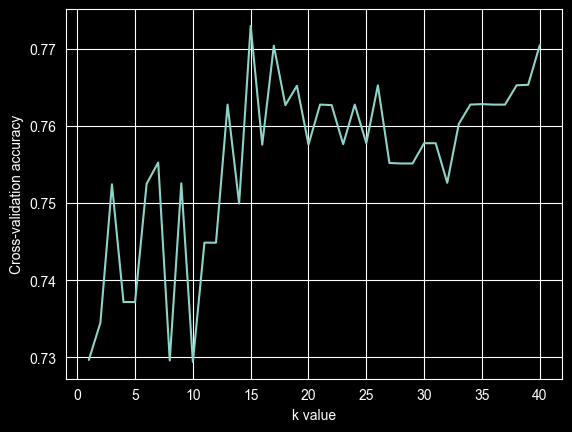

In [106]:
#Visualise best k number

plt.plot(k_range, k_scores)
plt.xlabel ('k value')
plt.ylabel('Cross-validation accuracy')

In [107]:
best_k = list(k_range)[int(np.argmax(k_scores))]  # dihitung dari hasil CV, bukan ditulis manual
print("Optimal k =", best_k)

knn = make_pipeline(StandardScaler(), nei.KNeighborsClassifier(n_neighbors=best_k))
knn.fit(inputs_train, outputs_train)

Optimal k = 15


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",15
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on then

In [108]:
(knn.predict(inputs_test) == outputs_test).sum()

np.int64(98)

In [109]:
outputs_pred = knn.predict(inputs_test)
accuracy = metrics.accuracy_score(outputs_test, outputs_pred)
accuracy #76.1%

0.7538461538461538

In [110]:
# 10-fold cross-validation with optimal k

scores = cross_val_score (knn, inputs, outputs, cv=skf, scoring = 'accuracy')
scores #accuracy scores arrays (from 61.5% to 84.6%)

array([0.85      , 0.7       , 0.82051282, 0.71794872, 0.84615385,
       0.76923077, 0.76923077, 0.76923077, 0.71794872, 0.76923077])

In [111]:
# Average accuracy score

scores.mean()

np.float64(0.772948717948718)

## Cross Validation

### Recursive feature elimination with cross-validation

In [112]:
# RFECV membutuhkan koefisien yang sebanding antar fitur -> skala-kan dulu
inputs_scaled = pd.DataFrame(StandardScaler().fit_transform(inputs), columns=inputs.columns, index=inputs.index)
lg = LogisticRegression(max_iter=1000)

In [113]:
rfecv = RFECV (estimator=lg,step=1, cv=skf, scoring='accuracy')

In [114]:
rfecv.fit(inputs_scaled, outputs)

,estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance either through a ``coef_``attribute or through a ``feature_importances_`` attribute.,LogisticRegre...max_iter=1000)
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.Note that the last iteration may remove fewer than ``step`` features inorder to reach ``min_features_to_select``.",1
,"min_features_to_select min_features_to_select: int, default=1The minimum number of features to be selected. This number of featureswill always be scored, even if the difference between the originalfeature count and ``min_features_to_select`` isn't divisible by``step``... versionadded:: 0.20",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds.- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If theestimator is not a classifier or if ``y`` is neither binary nor multiclass,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value of None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"scoring scoring: str or callable, default=NoneScoring method to evaluate the :class:`RFE` selectors' performance. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: the `estimator`'s :ref:`default evaluation criterion ` is used.",'accuracy'
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"n_jobs n_jobs: int or None, default=NoneNumber of cores to run in parallel while fitting across folds.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionadded:: 0.18",None
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance.For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case of:class:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must

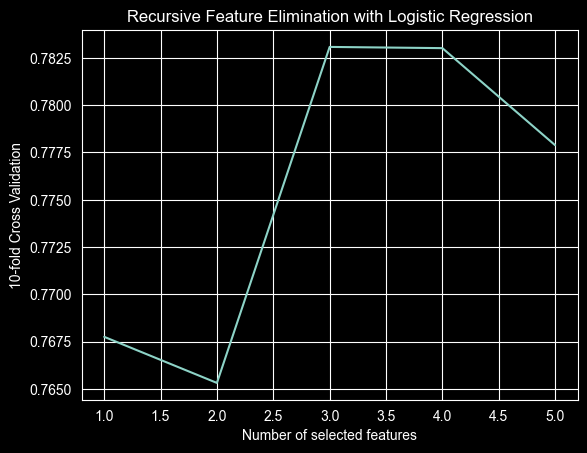

Jumlah fitur optimal: 3


In [115]:
scores_rfe = rfecv.cv_results_['mean_test_score']  # grid_scores_ sudah dihapus di sklearn >= 1.2
plt.figure()
plt.title('Recursive Feature Elimination with Logistic Regression')
plt.xlabel('Number of selected features')
plt.ylabel('10-fold Cross Validation')
plt.plot(range(1, len(scores_rfe) + 1), scores_rfe)
plt.show()
print("Jumlah fitur optimal:", rfecv.n_features_)

In [116]:
feature_names = inputs.columns  # harus kolom yang dipakai RFECV, bukan pima_all.columns
feature_names

Index(['Glucose', 'Insulin', 'SkinThickness', 'BMI', 'Age'], dtype='str')

In [117]:
new_features = [f for f, keep in zip(feature_names, rfecv.support_) if keep]
new_features

['Glucose', 'BMI', 'Age']

##### new_features adalah fitur terbaik hasil RFECV: Glucose, BMI, Age.

### Knn and Accuracy score - new features (inputs) and optimal k value

In [118]:
new_inputs = inputs[new_features]  # diambil dari hasil RFECV, bukan ditulis manual

In [119]:
knn = make_pipeline(StandardScaler(), nei.KNeighborsClassifier(n_neighbors=best_k))

In [120]:
knn.fit(new_inputs, outputs)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",15
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on then

In [121]:
(knn.predict(new_inputs) == outputs).sum()

np.int64(302)

In [122]:
# Pakai split yang SAMA dengan sebelumnya (split ulang menyebabkan label tidak sejajar dengan inputs_train)
new_inputs_train, new_inputs_test = inputs_train[new_features], inputs_test[new_features]

In [123]:
knn.fit(new_inputs_train, outputs_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",15
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on then

In [124]:
(knn.predict(new_inputs_test) == outputs_test).sum()

np.int64(100)

In [125]:
outputs_pred_new_inputs = knn.predict(new_inputs_test)
accuracy = metrics.accuracy_score(outputs_test, outputs_pred_new_inputs)
accuracy

0.7692307692307693

In [126]:
scores = cross_val_score (knn, new_inputs, outputs, cv =10, scoring = 'accuracy')
scores.mean()

np.float64(0.7704487179487179)

### Logistic Regression

In [127]:
lg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

In [128]:
lg_accuracy = cross_val_score(lg,inputs,outputs,cv=skf,scoring='accuracy')

In [129]:
lg_accuracy.mean()

np.float64(0.7778846153846153)

##### Logistic Regression (akurasi CV ≈ 0.778) sedikit lebih baik dari KNN (≈ 0.773 dengan k optimal) dan Naive Bayes.

In [130]:
lg.fit(inputs_train,outputs_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some 

In [131]:
outputs_pred=lg.predict(inputs_test)
accuracy_lg = metrics.accuracy_score(outputs_test, outputs_pred)
accuracy_lg

0.8153846153846154

### Naive Bayes

In [132]:
# GaussianNB: sesuai untuk fitur kontinu (MultinomialNB untuk data hitungan/frekuensi)
gnb = GaussianNB()
gnb.fit(inputs_train, outputs_train)
out_pred = gnb.predict(inputs_test)
accuracy_gnb = accuracy_score(outputs_test, out_pred)
accuracy_gnb

0.7615384615384615

### Confusion Matrix

In [133]:
conf_mtx_nb = metrics.confusion_matrix(outputs_test, out_pred)
conf_mtx_nb

array([[71, 16],
       [15, 28]])

In [134]:
conf_mtx_new_features = metrics.confusion_matrix(outputs_test, outputs_pred_new_inputs)
conf_mtx_new_features

array([[74, 13],
       [17, 26]])

##### Pada test set terdapat 43 perempuan diabetes dan 87 non-diabetes.
##### Gaussian Naive Bayes: TN=71, FP=16, FN=15, TP=28.
##### KNN fitur baru (Glucose, BMI, Age): TN=74, FP=13, FN=17, TP=26.

### Precision

In [135]:
precision_nb = metrics.precision_score(outputs_test, out_pred)
precision_nb

0.6363636363636364

In [136]:
precision_new_features = metrics.precision_score(outputs_test,outputs_pred_new_inputs)
precision_new_features

0.6666666666666666

##### Precision KNN fitur baru ≈ 66.7%; Gaussian NB ≈ 63.6%.

### Recall

In [137]:
recall = metrics.recall_score(outputs_test, out_pred)
recall

0.6511627906976745

In [138]:
recall_new_features = metrics.recall_score(outputs_test,outputs_pred_new_inputs)
recall_new_features

0.6046511627906976

##### Recall KNN fitur baru ≈ 60.5%; Gaussian NB ≈ 65.1%.

In [139]:
class_rep = classification_report(outputs_test, out_pred)
class_rep

'              precision    recall  f1-score   support\n\n           0       0.83      0.82      0.82        87\n           1       0.64      0.65      0.64        43\n\n    accuracy                           0.76       130\n   macro avg       0.73      0.73      0.73       130\nweighted avg       0.76      0.76      0.76       130\n'

In [140]:
out_pred_prob = gnb.predict_proba(inputs_test)[:,1]
out_pred_prob

array([0.02013736, 0.99878429, 0.99310533, 0.01931278, 0.37027351,
       0.06296403, 0.02518636, 0.02067042, 0.95193384, 0.03579538,
       0.73883734, 0.01171454, 0.04380064, 0.00633174, 0.06215892,
       0.99892743, 0.02275553, 0.24144094, 0.65229284, 0.33181402,
       0.0182998 , 0.99120697, 0.98459658, 0.02566784, 0.66712488,
       0.24353125, 0.63356322, 0.50793203, 0.8160231 , 0.63649281,
       0.01421191, 0.0861715 , 0.99123725, 0.86713397, 0.70033063,
       0.97647208, 0.24273617, 0.86942635, 0.08424017, 0.01931499,
       0.00460116, 0.17967093, 0.06671708, 0.01244602, 0.28964833,
       0.12313076, 0.18123916, 0.0996665 , 0.01549186, 0.98521585,
       0.0427525 , 0.99022473, 0.99966671, 0.97526938, 0.99993091,
       0.10109802, 0.88010367, 0.54245825, 0.03021377, 0.98143328,
       0.04719955, 0.00884419, 0.75289924, 0.47763262, 0.31790331,
       0.68610268, 0.13656955, 0.98573854, 0.00409199, 0.2629559 ,
       0.00887797, 0.02958714, 0.07527622, 0.9563048 , 0.16713

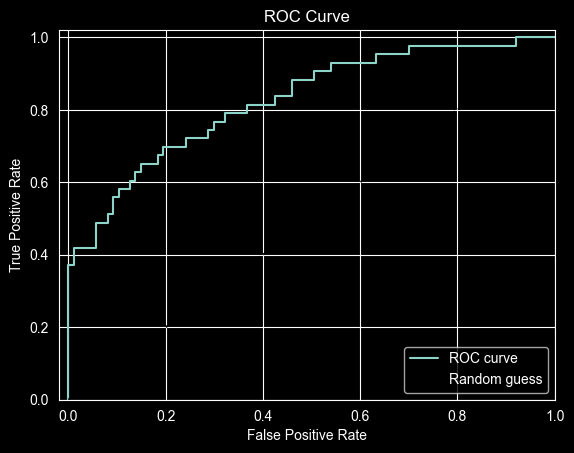

In [141]:
fpr, tpr, thresholds = roc_curve(outputs_test, out_pred_prob)
# create plot
plt.plot(fpr, tpr, label='ROC curve')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
_ = plt.xlabel('False Positive Rate')
_ = plt.ylabel('True Positive Rate')
_ = plt.title('ROC Curve')
_ = plt.xlim([-0.02, 1])
_ = plt.ylim([0, 1.02])
_ = plt.legend(loc="lower right")

In [142]:
ras = roc_auc_score(outputs_test, out_pred_prob)
ras

0.8251804330392943

##### ROC AUC Gaussian NB ≈ 0.83, cukup baik membedakan kelas, tetapi recall ~65% berarti masih banyak kasus diabetes yang terlewat.

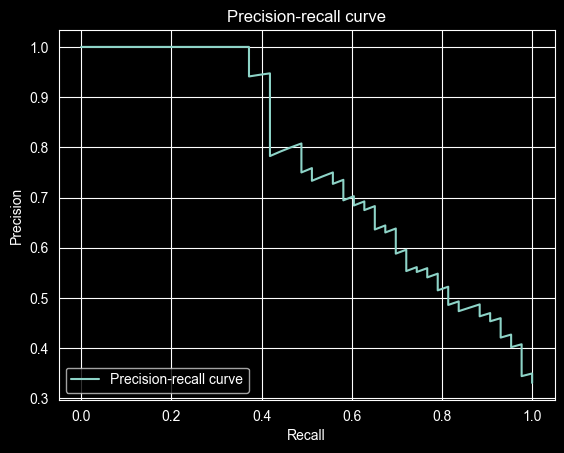

In [143]:
prec_curve, rec_curve, thresholds = precision_recall_curve(outputs_test, out_pred_prob)
# create plot (sumbu x = recall, sumbu y = precision; nama variabel tidak menimpa `recall` skalar)
plt.plot(rec_curve, prec_curve, label='Precision-recall curve')
_ = plt.xlabel('Recall')
_ = plt.ylabel('Precision')
_ = plt.title('Precision-recall curve')
_ = plt.legend(loc="lower left")

In [144]:
aps = average_precision_score(outputs_test, out_pred_prob)
aps

0.7674488214557541

##### Average precision ≈ 0.77 (bukan rendah; baseline = proporsi positif ≈ 0.33).

## CONCLUSION

##### Main conclusions will be written HERE!

+ Glucose, BMI, Age, dan Diabetes Pedigree Function adalah prediktor signifikan; model logistik sederhana (akurasi ≈ 78-79%) sudah setara KNN dan Naive Bayes.
+ Nilai 0 pada Glucose, BloodPressure, SkinThickness, Insulin, BMI adalah data hilang dan harus ditangani (dibuang atau diimputasi).

## REFERENCE

1. TYNECKI P. Predict diabetes diagnosis for Pima Female Indians with Logistic Regression. 2018. Available on: https://www.kaggle.com/ptynecki/pima-indians-diabetes-prediction-with-lr-84.
2. SCHULZ LO, CHAUDHARI LS. High-Risk Populations: The Pimas of Arizona and Mexico
Curr Obes Rep. 2015 Mar 1; 4(1): 92–98. Available on: https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4418458/
3. RUIZ-ALEJOS A, CARRILLO-LARCO RM, MIRANDA JJ, GILMAN RH, SMEETH L, BERNABE-Ortiz A. Skinfold thickness and the incidence of type 2 diabetes mellitus and hypertension: an analysis of the PERU MIGRANT study. Public Health Nutr. 2020;23(1):63-71. doi:10.1017/S1368980019001307
4. FRYAR CD, GU Q, OGDEN CL. Anthropometric reference data for children and adults: United States, 2007–2010. National Center for Health Statistics. Vital Health Stat 11(252). 2012.
5. VAN GAAL L., SCHEEN A. Weight Management in Type 2 Diabetes: Current and Emerging Approaches to Treatment, Diabetes Care 2015; 38(6): 1161 - 1172. Available on http://care.diabetesjournals.org/content/38/6/1161.
6. WILDING JPH. The importance of weight management in type 2 diabetes mellitus. Int J Clin Pract. 2014 Jun; 68(6): 682–691. Available on: https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4238418/
7. KODESH I. Associations between Variables Regarding Diabetes for Pima Indian Women. Available on: https://rpubs.com/ikodesh/53189.
8. DIABETES UK. Oral Glucose Tolerance Test. 2019. Available on: https://www.diabetes.co.uk/oral-glucose-tolerance-test.html
9. NATIONAL INSTITUTE FOR HEALTH AND CARE EXCELLENCE - NICE. Guideline Hypertension in adults: diagnosis and management. 2019. Available on: https://www.nice.org.uk/guidance/ng136/documents/draft-guideline
10. BOER IH, BANGALORE S, BENETOS A, DAVIS AM, MICHOS ED, MUNTNER P, ROSSING P, ZOUNGAS S, BAKRIS G. Diabetes and Hypertension: A Position Statement by the American Diabetes Association. Diabetes Care 2017 Sep; 40(9): 1273-1284.
11. BLOOD PRESSURE UK. Low Blood Pressure. Available on:  http://www.bloodpressureuk.org/microsites/u40/Home/facts/Whatislow#:~:text=For%20instance%2C%20when%20the%20heart,between%2040%20to%20160%20mmHg.
12. CHANDRA-SELVI E, PAVITHRA N, SAIKUMAR P. Skin Fold Thickness in Diabetes Mellitus: A Simple Anthropometric Measurement May Bare the Different Aspects of Adipose Tissue. IOSR Journal of Dental and Medical Sciences (IOSR-JDMS) e-ISSN: 2279-0853, p-ISSN: 2279-0861.Volume 15, Issue 11 Ver. IX (November. 2016), PP 07-11.
13. https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4287763/
14. https://www.sciencedirect.com/science/article/pii/S1646343913000734
15. https://www.ncbi.nlm.nih.gov/pmc/articles/PMC3417105/

# END